In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

In [3]:
df = pd.read_csv(r"C:\Users\Pratyaksh Tiwari\Downloads\diabetes - diabetes.csv")
print(df.head())

print("\nShape of dataset:", df.shape)

print("\nDataset Information: ")
df.info()

print("\nStatistical Information: ")
print(df.describe())

print("\nMissing values: ")
df.isnull().sum()

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Shape of dataset: (768, 9)

Dataset Information: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [3]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

for col in cols:
    df[col] = df[col].replace(0, np.nan)

df.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [26]:
for col in cols:
    df[col].fillna(df[col].median())

df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [41]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [6]:
df = df.drop_duplicates()

print(df.shape)

(768, 9)


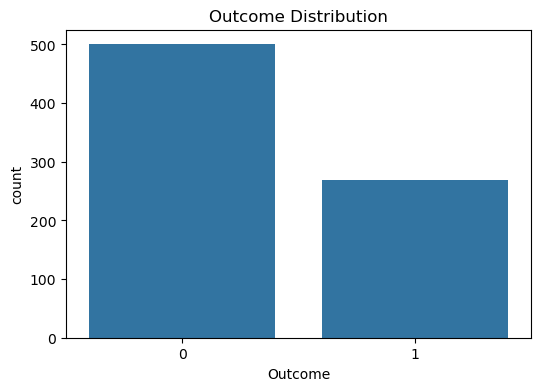

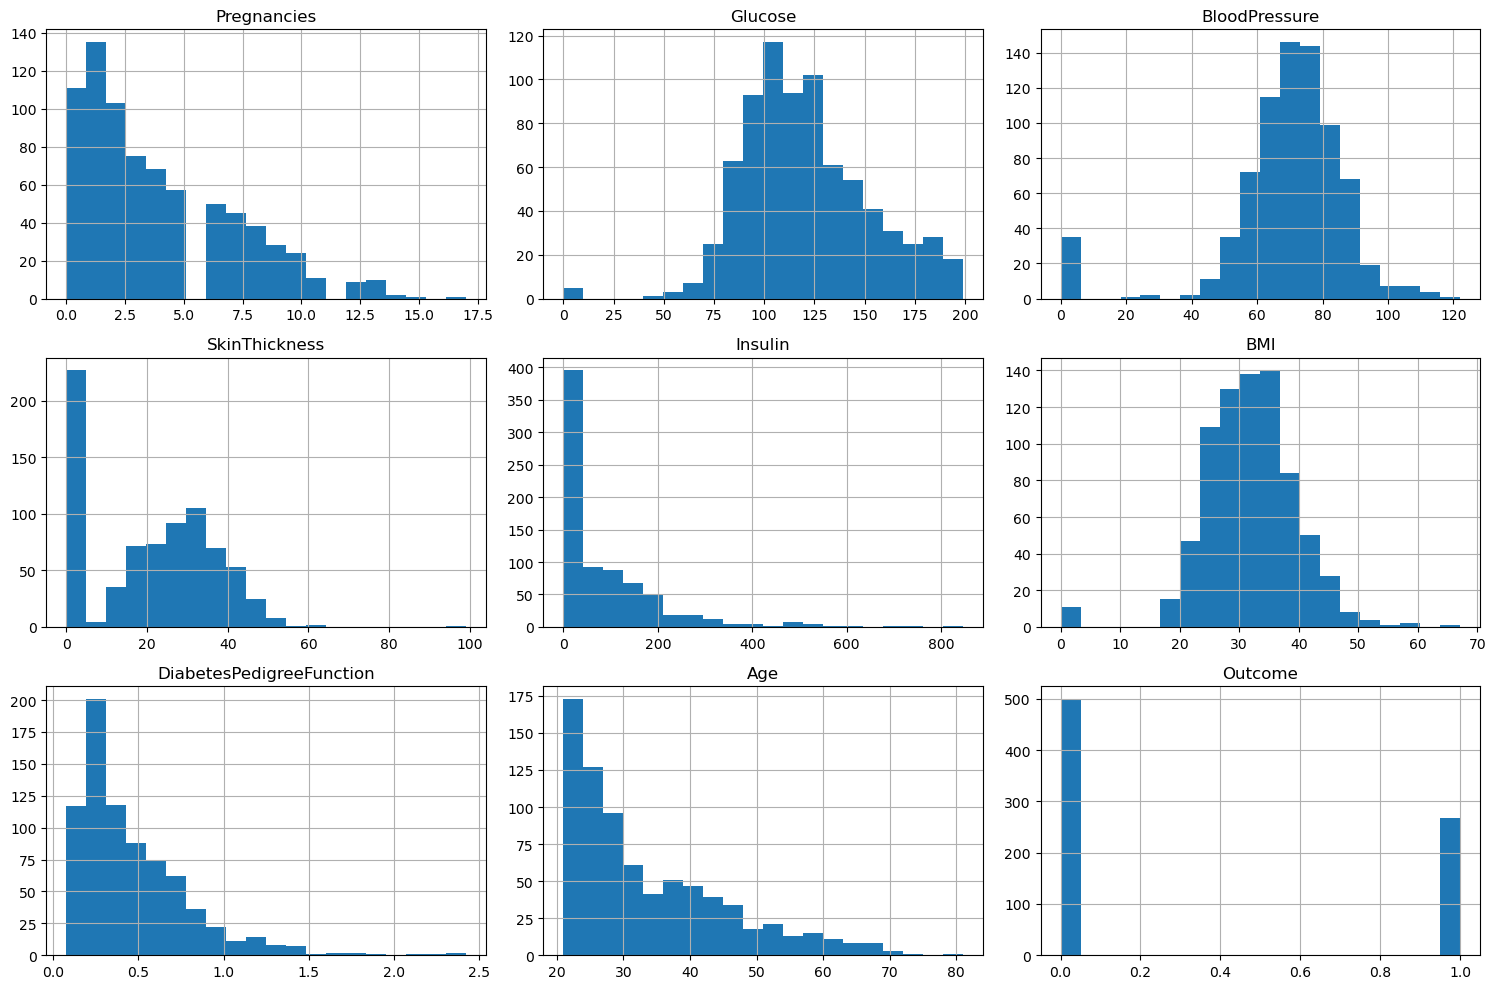

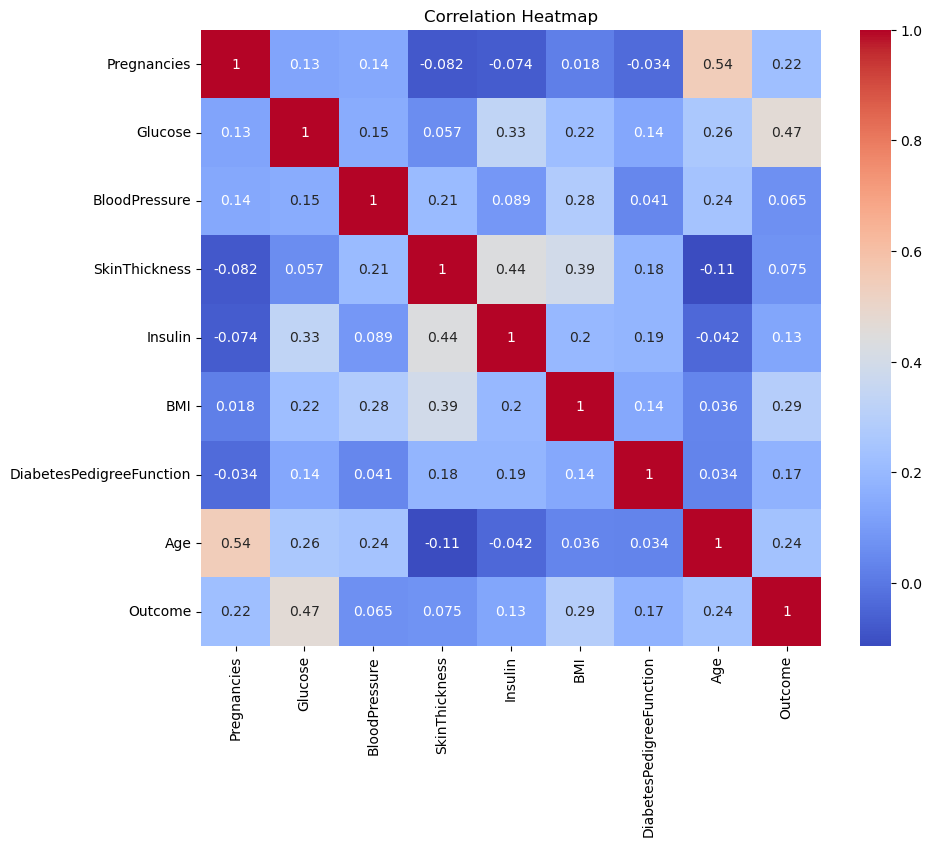

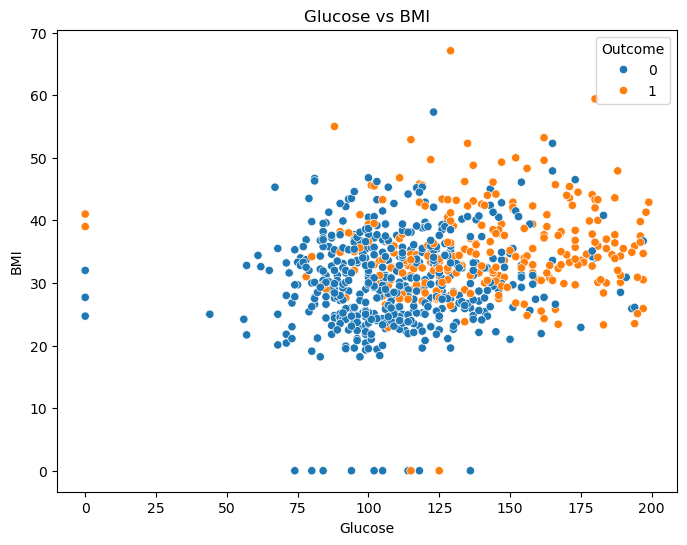

In [37]:
plt.figure(figsize=(6,4))

sns.countplot(x='Outcome', data=df)

plt.title("Outcome Distribution")
plt.show()

df.hist(figsize=(15,10), bins=20)

plt.tight_layout()
plt.show()

plt.figure(figsize=(10,8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

plt.figure(figsize=(8,6))

sns.scatterplot(x='Glucose', y='BMI', hue='Outcome', data=df)

plt.title("Glucose vs BMI")
plt.show()

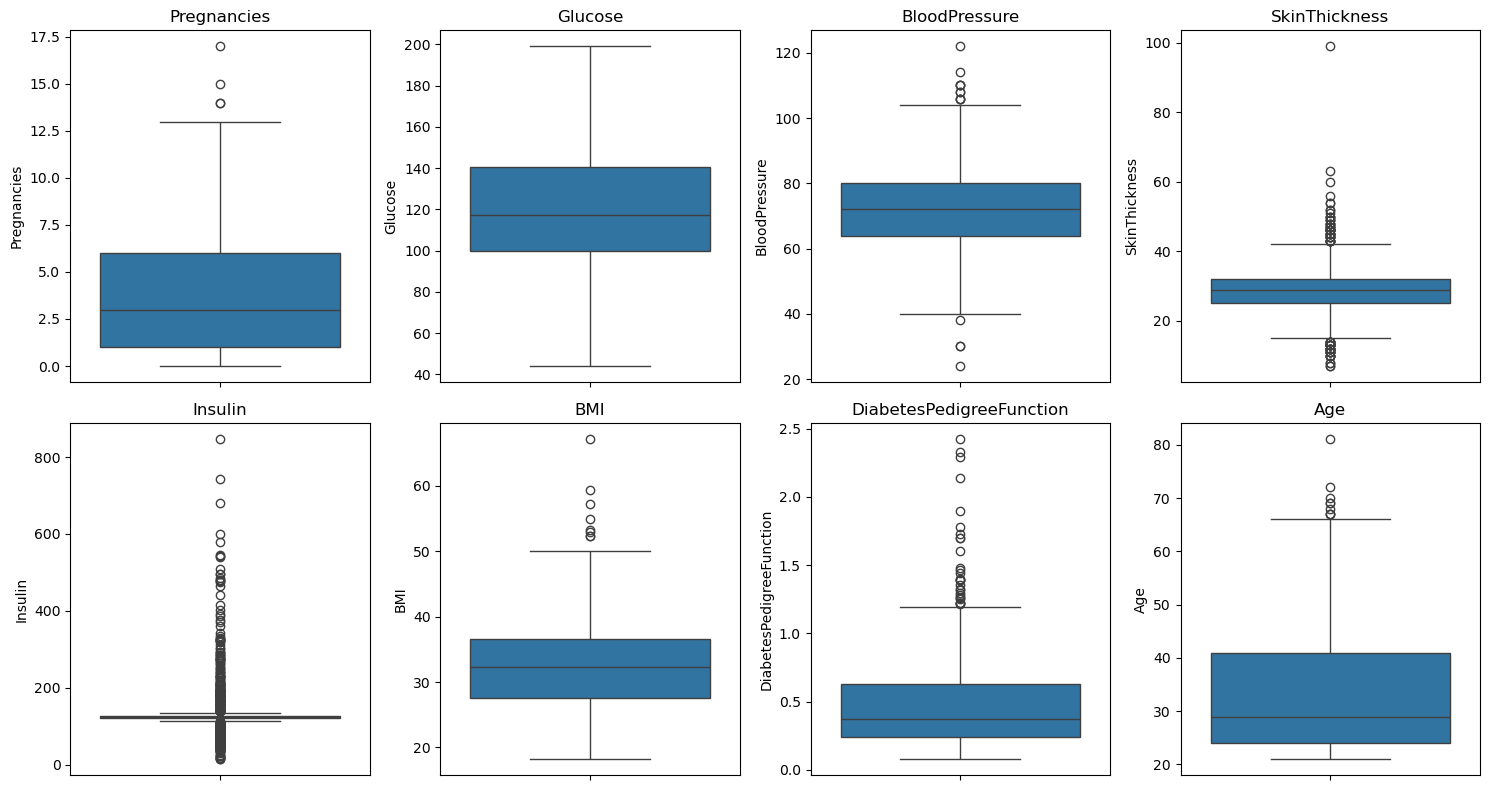

In [8]:
plt.figure(figsize=(15,8))

for i, col in enumerate(df.columns[:-1]):

    plt.subplot(2,4,i+1)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()
plt.show()

In [9]:
def remove_outliers(df, columns):

    for col in columns:

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        df = df[(df[col] >= lower) & (df[col] <= upper)]

    return df

df_clean = remove_outliers(df, df.columns[:-1])

print("Original Shape:", df.shape)
print("After Outlier Removal:", df_clean.shape)

Original Shape: (768, 9)
After Outlier Removal: (332, 9)


In [10]:
X = df_clean.drop('Outcome', axis=1)

Y = df_clean['Outcome']

In [11]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [12]:
X_train, X_test, Y_train, Y_test = train_test_split(X_scaled, Y, test_size=0.2, random_state=42, stratify=Y)

print(X_train.shape)
print(X_test.shape)

(265, 8)
(67, 8)


In [13]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train, Y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [14]:
svm_model = SVC(kernel='rbf', probability=True)

svm_model.fit(X_train, Y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [15]:
lr_pred = lr_model.predict(X_test)

lr_accuracy = accuracy_score(Y_test, lr_pred)

print("Logistic Regression Accuracy:")
print(round(lr_accuracy*100,2),"%")

Logistic Regression Accuracy:
82.09 %


In [16]:
svm_pred = svm_model.predict(X_test)

svm_accuracy = accuracy_score(Y_test, svm_pred)

print("SVM Accuracy:")
print(round(svm_accuracy*100,2),"%")

SVM Accuracy:
71.64 %


In [17]:
comparison = pd.DataFrame({
    'Model':['Logistic Regression', 'SVM'],
    'Accuracy':[lr_accuracy*100, svm_accuracy*100]
})

comparison

,Model,Accuracy
0,Logistic Regression,82.089552
1,SVM,71.641791


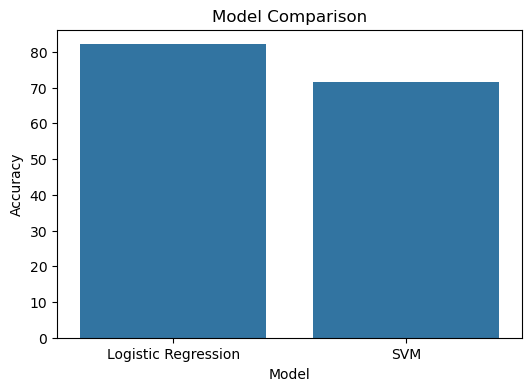

In [18]:
plt.figure(figsize=(6,4))

sns.barplot(x='Model', y='Accuracy', data=comparison)

plt.title("Model Comparison")

plt.show()

In [19]:
print(classification_report(Y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.80      0.98      0.88        44
           1       0.92      0.52      0.67        23

    accuracy                           0.82        67
   macro avg       0.86      0.75      0.77        67
weighted avg       0.84      0.82      0.81        67



In [20]:
print(classification_report(Y_test, svm_pred))

              precision    recall  f1-score   support

           0       0.75      0.86      0.80        44
           1       0.62      0.43      0.51        23

    accuracy                           0.72        67
   macro avg       0.69      0.65      0.66        67
weighted avg       0.70      0.72      0.70        67



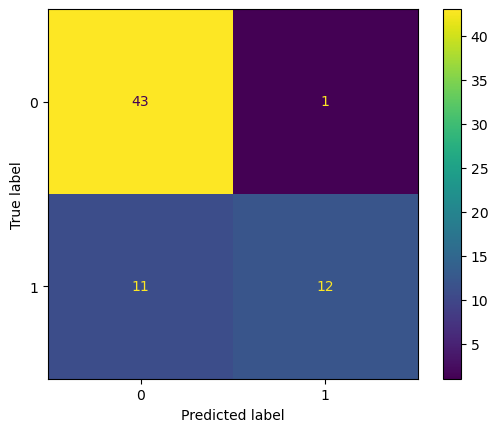

In [21]:
cm = confusion_matrix(Y_test, lr_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot()

plt.show()

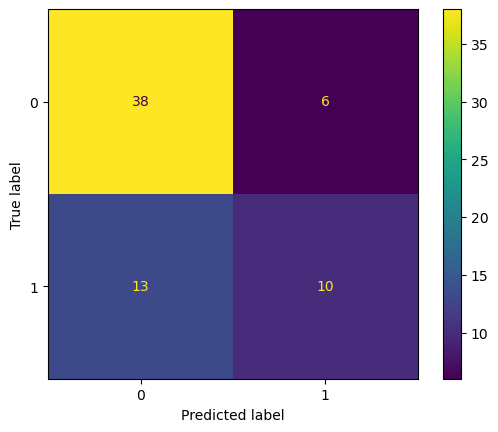

In [22]:
cm = confusion_matrix(Y_test, svm_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot()

plt.show()

In [27]:
def predict_diabetes(patient_data, model_name):

    patient_df = pd.DataFrame(
        [patient_data],
        columns=X.columns
    )

    patient_scaled = scaler.transform(patient_df)

    if model_name.lower() == "svm":

        prediction = svm_model.predict(patient_scaled)

    else:

        prediction = lr_model.predict(patient_scaled)

    if prediction[0] == 1:

        print("Patient is likely Diabetic")

    else:

        print("Patient is likely Non-Diabetic")

In [29]:
sample_patient = (5, 166, 72, 19, 175, 25.8, 0.587, 51)

predict_diabetes(sample_patient, "svm")

predict_diabetes(sample_patient, "logistic")

Patient is likely Non-Diabetic
Patient is likely Diabetic


In [44]:
print("\nEnter Patient Details\n")

preg = float(input("Pregnancies: "))
glu = float(input("Glucose: "))
bp = float(input("Blood Pressure: "))
skin = float(input("Skin Thickness: "))
insulin = float(input("Insulin: "))
bmi = float(input("BMI: "))
dpf = float(input("Diabetes Pedigree Function: "))
age = float(input("Age: "))

model_choice = input("\nChoose Model (svm/logistic): ")

sample_data = (preg, glu, bp, skin, insulin, bmi, dpf, age)

predict_diabetes(sample_data, model_choice)


Enter Patient Details



Pregnancies:  2
Glucose:  160
Blood Pressure:  70
Skin Thickness:  20
Insulin:  170
BMI:  26
Diabetes Pedigree Function:  0.8
Age:  50

Choose Model (svm/logistic):  logistic


Patient is likely Diabetic
